<a href="https://colab.research.google.com/github/MC-369/Error-Analysis-Agent/blob/main/error_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
   !pip install ultralytics pycocotools opencv-python pandas anthropic

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 34.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 80.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]


In [2]:
from pathlib import Path
import numpy as np, pandas as pd, cv2
from ultralytics import YOLO
from ultralytics.utils.downloads import download

download("https://github.com/ultralytics/assets/releases/download/v0.0.0/coco128.zip",
         dir="/content/datasets")

img_dir = Path("/content/datasets/coco128/images/train2017")
lbl_dir = Path("/content/datasets/coco128/labels/train2017")
model = YOLO("yolov8n.pt")

def iou(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    ua = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / ua if ua > 0 else 0

def load_gt(p, w, h):
    f = lbl_dir / (p.stem + ".txt")
    boxes = []
    if f.exists():
        for line in f.read_text().splitlines():
            c, x, y, bw, bh = line.split()[:5]
            if int(c) == 0:  # class 0 = person
                x, y, bw, bh = float(x)*w, float(y)*h, float(bw)*w, float(bh)*h
                boxes.append([x-bw/2, y-bh/2, x+bw/2, y+bh/2])
    return boxes

def size_bucket(b):
    area = (b[2]-b[0]) * (b[3]-b[1])
    return "small" if area < 32**2 else "medium" if area < 96**2 else "large"

rows = []
for p in sorted(img_dir.glob("*.jpg")):
    img = cv2.imread(str(p)); h, w = img.shape[:2]
    brightness = float(img.mean())
    blur = float(cv2.Laplacian(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), cv2.CV_64F).var())
    gts = load_gt(p, w, h)
    res = model.predict(img, classes=[0], conf=0.25, verbose=False)[0]
    preds = list(zip(res.boxes.xyxy.cpu().numpy().tolist(),
                     res.boxes.conf.cpu().numpy().tolist()))
    matched = set()
    base = dict(image=p.name, brightness=brightness, blur=blur, n_people=len(gts))

    for pb, conf in sorted(preds, key=lambda t: -t[1]):
        ious = [iou(pb, g) for g in gts]
        j = int(np.argmax(ious)) if ious else -1
        best = ious[j] if ious else 0
        if best >= 0.5 and j not in matched:
            matched.add(j); kind = "correct"
        elif best >= 0.5:
            kind = "duplicate"
        elif best >= 0.1:
            kind = "mislocalized"
        else:
            kind = "hallucinated"
        rows.append({**base, "error": kind, "box": pb, "conf": conf, "size": size_bucket(pb)})

    for j, g in enumerate(gts):
        if j not in matched:
            rows.append({**base, "error": "missed", "box": g, "conf": None, "size": size_bucket(g)})

df = pd.DataFrame(rows)
df.to_csv("/content/errors.csv", index=False)
print(df["error"].value_counts())
print(df[df.error.isin(["correct", "missed"])].groupby("size")["error"]
        .apply(lambda s: (s == "correct").mean()).rename("recall_by_size"))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Unzipping /content/datasets/coco128.zip to /content/datasets/coco128...: 100% ━━━━━━━━━━━━ 263/263 3.6Kfiles/s 0.1s
error
correct         167
missed           87
mislocalized     17
hallucinated      9
duplicate         7
Name: count, dtype: int64
size
large     0.894118
medium    0.702381
small     0.376471
Name: recall_by_size, dtype: float64


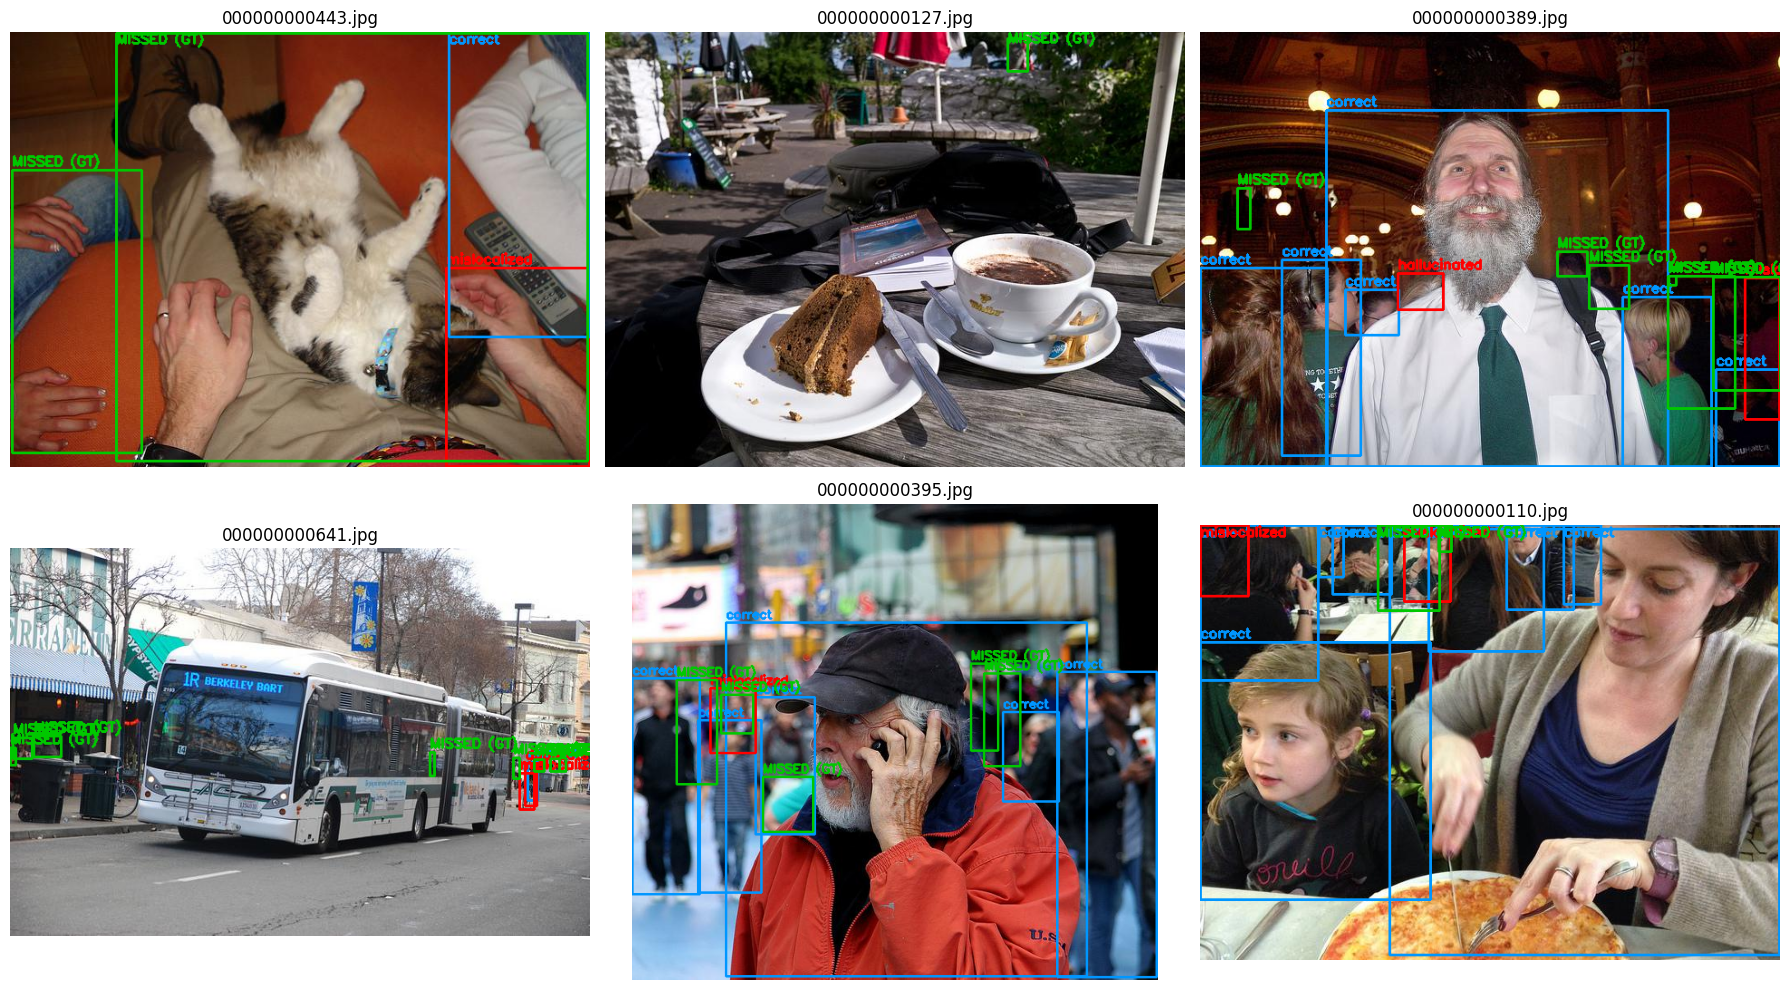

In [4]:
import matplotlib.pyplot as plt
import random

def draw(image_name):
    img = cv2.imread(str(img_dir / image_name))
    sub = df[df.image == image_name]
    for _, r in sub.iterrows():
        x1, y1, x2, y2 = map(int, r["box"])
        if r["error"] == "missed":
            color, label = (0, 200, 0), "MISSED (GT)"      # green: ground truth the model missed
        elif r["error"] == "correct":
            color, label = (255, 150, 0), "correct"         # blue-ish: correct detection
        else:
            color, label = (0, 0, 255), r["error"]          # red: hallucinated, mislocalized, duplicate
        cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
        cv2.putText(img, label, (x1, max(y1 - 5, 12)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# show images that actually contain people
#people_imgs = df[df.n_people > 0].image.unique().tolist()
#sample = random.sample(people_imgs, min(6, len(people_imgs)))

bad = df[df.error.isin(["missed", "hallucinated", "mislocalized"])].image.unique().tolist()
sample = random.sample(bad, min(6, len(bad)))

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, name in zip(axes.flat, sample):
    ax.imshow(draw(name))
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [10]:
import time
from google import genai
from google.genai import types
from google.colab import userdata

client = genai.Client(api_key=userdata.get("GEMINI_API_KEY"))

MODELS = ["gemini-3.1-flash-lite", "gemini-3-flash-preview"]  # tried in this order
MODEL = MODELS[0]  # used later by the agent cell

def ask_gemini(contents, tries=5):
    """Call Gemini, retrying and falling back to another model on 503/429."""
    for attempt in range(tries):
        for m in MODELS:
            try:
                return client.models.generate_content(model=m, contents=contents)
            except Exception as e:
                if "503" in str(e) or "429" in str(e):
                    continue          # try the next model
                raise                 # a real bug, show it
        time.sleep(2 ** attempt)      # wait 1, 2, 4, 8 seconds, then retry
    raise RuntimeError("Gemini still unavailable, try again later")

def explain_failure(image_name: str) -> str:
    """Show Gemini an annotated image and ask why the detector failed."""
    rgb = draw(image_name)
    ok, buf = cv2.imencode(".jpg", cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR))
    prompt = ("This is a person-detector's output. Green = person the model MISSED, "
              "red = wrong prediction, orange = correct. In 2 sentences, give the most "
              "likely reason for each failure (small, occluded, crowded, dark, blurry, "
              "cut off at the edge, or probable label error).")
    r = ask_gemini([types.Part.from_bytes(data=buf.tobytes(), mime_type="image/jpeg"), prompt])
    return r.text

bad = df[df.error.isin(["missed", "hallucinated"])].image.unique().tolist()
print(bad[0])
print(explain_failure(bad[0]))

000000000049.jpg
The missed person in the green box is likely overlooked due to being partially occluded and overlapping with the horse's body. The mislocalized red box is likely a classification error caused by the model incorrectly identifying part of the horse as a person, while the missed red box at the far right is likely due to the object being small and cut off at the edge of the frame.


In [12]:
def get_error_summary() -> dict:
    """Counts of each prediction outcome (correct, missed, hallucinated, mislocalized, duplicate)."""
    return df["error"].value_counts().to_dict()

def get_slice_metrics(slice_by: str) -> dict:
    """Recall of person detection per slice. slice_by must be one of: size, brightness, blur, crowding."""
    d = df[df.error.isin(["correct", "missed"])].copy()
    if slice_by == "size":
        d["g"] = d["size"]
    elif slice_by == "brightness":
        d["g"] = pd.qcut(d.brightness, 3, labels=["dark", "mid", "bright"], duplicates="drop")
    elif slice_by == "blur":
        d["g"] = pd.qcut(d.blur, 3, labels=["blurry", "mid", "sharp"], duplicates="drop")
    elif slice_by == "crowding":
        d["g"] = pd.cut(d.n_people, [0, 1, 4, 1000], labels=["1 person", "2-4", "5+"])
    else:
        return {"error": "slice_by must be size, brightness, blur, or crowding"}
    out = d.groupby("g", observed=True)["error"].agg(
        recall=lambda s: round((s == "correct").mean(), 3), n="count")
    return out.to_dict("index")

def sample_errors(error_type: str, n: int = 5) -> list:
    """Return up to n image names that contain the given error type."""
    names = df[df.error == error_type].image.unique().tolist()
    return random.sample(names, min(n, len(names)))

def view_failure(image_name: str) -> str:
    """Look at an annotated image and get a visual explanation of why the detector failed."""
    return explain_failure(image_name)

SYSTEM = ("You are an ML engineer analyzing a person detector's failures. Start with the "
          "error summary, form hypotheses, test them with slice metrics, verify by viewing "
          "a few failure images, then write a report: ranked failure modes, the numbers "
          "backing each, example image names, and concrete fixes.")

resp = client.models.generate_content(
    model=MODEL,
    contents="Analyze this detector and write the error analysis report.",
    config=types.GenerateContentConfig(
        system_instruction=SYSTEM,
        tools=[get_error_summary, get_slice_metrics, sample_errors, view_failure],
    ),
)
print(resp.text)

# Person Detector Error Analysis Report

## Executive Summary
The person detector shows solid performance in clear, well-lit environments, but struggles significantly with small objects and crowded scenes. Out of 287 total occurrences, we have 167 correct detections and 120 failures.

---

## Ranked Failure Modes

| Failure Mode | Frequency | Key Metric/Observation |
| :--- | :--- | :--- |
| **Missed Detections (Small)** | 53 | Recall for "small" objects is only **37.6%**. |
| **Missed Detections (Crowding)** | 34 | Recall for "5+ people" is only **61.2%**. |
| **Mislocalization** | 17 | Occurs frequently with occlusions. |
| **Hallucinations** | 9 | Low impact, but requires monitoring. |

---

## Detailed Findings

### 1. Small Object Sensitivity (Primary Failure)
The detector has a drastic drop-off in performance as person size decreases. With a recall of 37.6% for small objects compared to 89.4% for large ones, this is the most critical area for improvement. Visual inspection confir